## Searching the hyperparameters

We now will apply a grid-search to find the best hyperparameters for our model.

In [39]:
%reload_ext autoreload
%autoreload 2
import numpy as np
from implementations import *
from helpers import *
from aux_exploratory_data_analysis import *
from aux_cleaning_functions import *
from aux_preprocessing import *
from aux_grid_search import *
import csv

In [40]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data")
# We transform the data form (-1,1) to (0,1) 
Y_tr = (y_train + 1) / 2

In [41]:
x_train, x_validation, x_te, y_train, y_validation, y_te = split_data(x_train, Y_tr, ratiotrain=0.7, ratiovalidation=0.15, seed=None)

print (x_train.shape, y_train.shape)
print (x_validation.shape, y_validation.shape)
print (x_te.shape, y_te.shape)

(229694, 321) (229694,)
(49220, 321) (49220,)
(49221, 321) (49221,)


We will compute a grid-search over the hyperparameters of the model. We are going to divide the training dataset into a 30% batch of it than mantains the ratio between positive and negative cases due to computational costs. We will compare the modelsby using the f2 score. With this we want to minimize the false negatives, giving more importance to the recall of the model, rather than the accuracy of it as we are working on a medical classification problem. 

In [42]:
best_params, best_f1, results = grid_search_logistic_wheight(
    y_train, x_train,
    y_validation, x_validation,
    thershold_nans = [0.4, 0.3],
    pos_weights=[3, 5, 7, 9],
    methods = ["undersample","weighted"],
    lambdas=[1e-4, 1e-3, 1e-2],
    thresholds=[0.4, 0.5, 0.6, 0.7],
    max_iter= 1000,
    gammas= [0.01, 0.05, 0.1], 
    random_seed = 42
)


=== Run 1/78 (method=undersample,thr_nans = 0.4,gamma = 0.01) ===
Iter     0 | Loss = 0.691291 | Grad = 0.4316
Iter   100 | Loss = 0.585386 | Grad = 0.2424
Iter   200 | Loss = 0.546391 | Grad = 0.1610
Iter   300 | Loss = 0.527279 | Grad = 0.1191
Iter   400 | Loss = 0.516078 | Grad = 0.0944
Iter   500 | Loss = 0.508711 | Grad = 0.0783
Iter   600 | Loss = 0.503466 | Grad = 0.0672
Iter   700 | Loss = 0.499515 | Grad = 0.0590
Iter   800 | Loss = 0.496411 | Grad = 0.0528
Iter   900 | Loss = 0.493890 | Grad = 0.0479
New best F_beta = 0.5135 (threshold = 0.40)
New best F_beta = 0.5262 (threshold = 0.50)

=== Run 2/78 (method=weighted,thr_nans = 0.4,gamma = 0.01, lambda = 0.0001, pw = 3) ===

=== Run 3/78 (method=weighted,thr_nans = 0.4,gamma = 0.01, lambda = 0.0001, pw = 5) ===

=== Run 4/78 (method=weighted,thr_nans = 0.4,gamma = 0.01, lambda = 0.0001, pw = 7) ===

=== Run 5/78 (method=weighted,thr_nans = 0.4,gamma = 0.01, lambda = 0.0001, pw = 9) ===

=== Run 6/78 (method=weighted,thr_nans

Now we will compute the full models with the 5 combinations of parameters that maximize the f2 score on the grid_search.

In [43]:
top_5_dicts = [
    {
        "thr_nans": r[0],
        "method": r[1],
        "gamma": r[2],
        "pos_weight": r[3],
        "lambda": r[4],
        "threshold": r[5],
        "fbeta": r[6]
    }
    for r in results[:5]
]

for candidate in top_5_dicts:
    print (f"Training candidate using {candidate['method']} with a value of f_beta score of {candidate['fbeta']}")

print (top_5_dicts[0])

Training candidate using undersample with a value of f_beta score of 0.5410262766484878
Training candidate using undersample with a value of f_beta score of 0.5406875543951262
Training candidate using undersample with a value of f_beta score of 0.5395995171922875
Training candidate using undersample with a value of f_beta score of 0.539573938734256
Training candidate using undersample with a value of f_beta score of 0.5330198610428802
{'thr_nans': 0.3, 'method': 'undersample', 'gamma': 0.05, 'pos_weight': None, 'lambda': None, 'threshold': 0.5, 'fbeta': np.float64(0.5410262766484878)}


We can see that the top four combinations of hyperparameters use the undersample method and the last one use the weighted logistic regression. We will make a comparation between the top combination using undersample method and the top combination using weighted method, as weighted is mathematically stronger than oversample (just random row duplication) we will not consider such option.

NOW WE WILL COMPARE BOTH MODELS 

Iter     0 | Loss = 0.684307 | Grad = 0.4241
Iter   100 | Loss = 0.509825 | Grad = 0.0781
Iter   200 | Loss = 0.493148 | Grad = 0.0437
Iter   300 | Loss = 0.486316 | Grad = 0.0316
Iter   400 | Loss = 0.482378 | Grad = 0.0251
Iter   500 | Loss = 0.479763 | Grad = 0.0209
Iter   600 | Loss = 0.477887 | Grad = 0.0180
Iter   700 | Loss = 0.476468 | Grad = 0.0158
Iter   800 | Loss = 0.475352 | Grad = 0.0141
Iter   900 | Loss = 0.474447 | Grad = 0.0128
Iter  1000 | Loss = 0.473695 | Grad = 0.0117
Iter  1100 | Loss = 0.473058 | Grad = 0.0109
Iter  1200 | Loss = 0.472510 | Grad = 0.0101
Iter  1300 | Loss = 0.472032 | Grad = 0.0095
Iter  1400 | Loss = 0.471612 | Grad = 0.0089
Iter  1500 | Loss = 0.471238 | Grad = 0.0084
Iter  1600 | Loss = 0.470904 | Grad = 0.0080
Iter  1700 | Loss = 0.470604 | Grad = 0.0076
Iter  1800 | Loss = 0.470331 | Grad = 0.0072
Iter  1900 | Loss = 0.470084 | Grad = 0.0069
Iter  2000 | Loss = 0.469857 | Grad = 0.0066
Iter  2100 | Loss = 0.469649 | Grad = 0.0063
Iter  2200

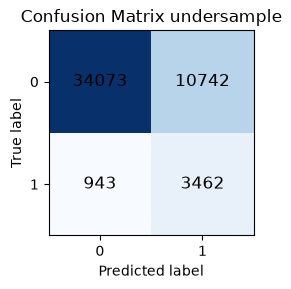

We have obtained a model using undersample with an accuracy of accuracy = 0.762596505485575, a recall of recall = 0.7859250851305335 and a fbeta score of F_beta = 0.5439291101055808
Iter     0 | Loss = 0.675430 | Grad = 0.4283
Iter   100 | Loss = 0.494766 | Grad = 0.0433
Iter   200 | Loss = 0.484197 | Grad = 0.0250
Iter   300 | Loss = 0.479740 | Grad = 0.0180
Iter   400 | Loss = 0.477202 | Grad = 0.0142
Iter   500 | Loss = 0.475528 | Grad = 0.0118
Iter   600 | Loss = 0.474325 | Grad = 0.0102
Iter   700 | Loss = 0.473412 | Grad = 0.0090
Iter   800 | Loss = 0.472693 | Grad = 0.0080
Iter   900 | Loss = 0.472114 | Grad = 0.0072
Iter  1000 | Loss = 0.471637 | Grad = 0.0066
Iter  1100 | Loss = 0.471238 | Grad = 0.0061
Iter  1200 | Loss = 0.470899 | Grad = 0.0056
Iter  1300 | Loss = 0.470608 | Grad = 0.0052
Iter  1400 | Loss = 0.470355 | Grad = 0.0049
Iter  1500 | Loss = 0.470132 | Grad = 0.0046
Iter  1600 | Loss = 0.469935 | Grad = 0.0043
Iter  1700 | Loss = 0.469758 | Grad = 0.0041
Iter  18

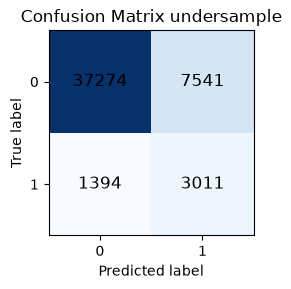

We have obtained a model using undersample with an accuracy of accuracy = 0.8184681023973994, a recall of recall = 0.6835414301929625 and a fbeta score of F_beta = 0.5343958540394719


In [44]:
final_candidates = [top_5_dicts[0], top_5_dicts[-1]]

modelweights = []
for candidate in final_candidates:
    thr_nans = candidate['thr_nans']
    method = candidate ['method']
    gamma = candidate ['gamma']
    pos_weight = candidate ['pos_weight']
    lambda_ = candidate ['lambda']
    threshold = candidate ['threshold']
    fbeta = candidate ['fbeta']

    X_tr_base = x_train.copy()
    y_tr_base = y_train.copy()
    X_val_base = x_validation.copy()
    y_val_base = y_validation.copy()
    keep_mask = remove_nan_feat(X_tr_base, threshold= thr_nans)

    X_clean_nan_tr = X_tr_base[:,keep_mask]
    X_clean_nan_val = X_val_base[:,keep_mask]
    cat_mask, num_mask = detect_categorical_features(X_clean_nan_tr, max_unique=30)

    X_imp_tr,medians_tr = impute_numerical(X_clean_nan_tr, num_mask, medians=None, means=None, strategy='medians')
    X_imp_tr,modes_tr = impute_categorical(X_imp_tr, cat_mask, modes=None)
    X_imp_val, _ = impute_numerical(X_clean_nan_val, num_mask, medians=medians_tr, strategy='medians')
    X_imp_val, _ = impute_categorical(X_imp_val, cat_mask, modes=modes_tr)
    

    X_std_tr, means_tr, stds_tr= standardize_features(X_imp_tr, num_mask, means=None, stds=None)
    X_std_val, _, _ = standardize_features(X_imp_val, num_mask, means=means_tr, stds=stds_tr)

    X_ohe_tr, categories = one_hot_encode(X_std_tr, cat_mask)   
    X_ohe_val, _ = one_hot_encode(X_std_val, cat_mask,categories = categories)

    mask = feature_target_correlation(X_ohe_tr, y_tr_base, threshold_elimination=0.01)
    X_cleaned_tr = X_ohe_tr[:, mask]
    mask_correlated_variables = filter_colinear_features (X_cleaned_tr, y_tr_base, 0.9)
    X_thr_train = X_cleaned_tr[:, mask_correlated_variables]
    X_thr_val = X_ohe_val[:, mask][:, mask_correlated_variables]

    if (method == 'undersample'):
        X_bal, Y_bal = balance_data (X_thr_train, y_tr_base,method = method, random_state=None)
        w,loss = logistic_regression(Y_bal, X_bal, np.zeros(X_bal.shape[1] + 1), 10000 ,gamma,1e-6)

    else:
        loss, w = logistic_regression_weighted_gd (y_tr_base, X_thr_train, lambda_= lambda_, gamma=gamma, pos_weight=pos_weight, neg_weight=1.0, max_iter=10000, verbose=False)

    modelweights.append(w)
    preds, _ = predict_with_threshold(X_thr_val, w, threshold=threshold)
    fbeta = f_beta_score(y_val_base, preds)
    acc = accuracy_numpy(y_val_base, preds)
    recall = recall_numpy(y_val_base, preds)
    cm = confusion_matrix_numpy(y_val_base, preds, method = method)
    print (f"We have obtained a model using {method} with an accuracy of accuracy = {acc}, a recall of recall = {recall} and a fbeta score of F_beta = {fbeta}")
    


So clearly we can see that the best option is to use the model using the undersample method, as we minimize the number of false negatives while mantaining a high number of corrected predicted outputs, we can notice such fact in the recall value. We can now set those parameters as the best paramters and just compute a final test computation on the best model.

Confusion Matrix:
[[34142 10683]
 [  915  3481]]
TN=34142, FP=10683, FN=915, TP=3481


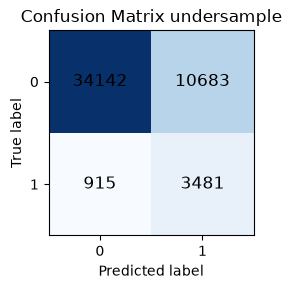

We have obtained a model using undersample with an accuracy of accuracy = 0.7643688669470348, a recall of recall = 0.7918562329390355 and a fbeta score of F_beta = 0.5482235101423711


In [45]:
winning_candidate = final_candidates[0]
best_weights = modelweights[0]

thr_nans = winning_candidate["thr_nans"]
opt_threshold = winning_candidate["threshold"]


X_tr_base = x_train.copy()
y_tr_base = y_train.copy()
X_te_base = x_te.copy()
y_te_base = y_te.copy()
keep_mask = remove_nan_feat(X_tr_base, threshold= thr_nans)

X_clean_nan_tr = X_tr_base[:,keep_mask]
X_clean_nan_te = X_te_base[:,keep_mask]
X_clean_nan_test = x_test[:,keep_mask]
cat_mask, num_mask = detect_categorical_features(X_clean_nan_tr, max_unique=30)

X_imp_tr,medians_tr = impute_numerical(X_clean_nan_tr, num_mask, medians=None, means=None, strategy='medians')
X_imp_tr,modes_tr = impute_categorical(X_imp_tr, cat_mask, modes=None)
X_imp_te, _ = impute_numerical(X_clean_nan_te, num_mask, medians=medians_tr, strategy='medians')
X_imp_te, _ = impute_categorical(X_imp_te, cat_mask, modes=modes_tr)
X_imp_test, _ = impute_numerical(X_clean_nan_test, num_mask, medians=medians_tr, strategy='medians')
X_imp_test, _ = impute_categorical(X_imp_test, cat_mask, modes=modes_tr)

X_std_tr, means_tr, stds_tr= standardize_features(X_imp_tr, num_mask, means=None, stds=None)
X_std_te, _, _ = standardize_features(X_imp_te, num_mask, means=means_tr, stds=stds_tr)
X_std_test, _, _ = standardize_features(X_imp_test, num_mask, means=means_tr, stds=stds_tr)


X_ohe_tr, categories = one_hot_encode(X_std_tr, cat_mask)   
X_ohe_te, _ = one_hot_encode(X_std_te, cat_mask,categories = categories)
X_ohe_test, _ = one_hot_encode(X_std_test, cat_mask,categories = categories)


mask = feature_target_correlation(X_ohe_tr, y_tr_base, threshold_elimination=0.01)
X_cleaned_tr = X_ohe_tr[:, mask]
mask_correlated_variables = filter_colinear_features (X_cleaned_tr, y_tr_base, 0.9)
X_thr_train = X_cleaned_tr[:, mask_correlated_variables]
X_thr_te = X_ohe_te[:, mask][:, mask_correlated_variables]
X_thr_test = X_ohe_test[:, mask][:, mask_correlated_variables]

preds, _ = predict_with_threshold(X_thr_te, best_weights, threshold = opt_threshold)
fbeta = f_beta_score(y_te_base, preds)
acc = accuracy_numpy(y_te_base, preds)
recall = recall_numpy(y_te_base, preds)
cm = confusion_matrix_numpy(y_te_base, preds, method = winning_candidate["method"])
print (f"We have obtained a model using {winning_candidate["method"]} with an accuracy of accuracy = {acc}, a recall of recall = {recall} and a fbeta score of F_beta = {fbeta}")
